## Fase 1: Diagnóstico y Calidad de Datos (EDA) con Enfoque de Negocio

El objetivo de esta fase es evaluar la salud financiera de la cartera para tomar decisiones informadas sobre el modelado. Analizaremos:

1. **Integridad de la Información:** Verificación de tipos de datos, nulos y registros duplicados.
2. **Coherencia Financiera (Reglas de Negocio):** Detección de inconsistencias (ingresos o préstamos negativos, Puntaje Crediticio fuera del rango 300-850, o Nivel de Endeudamiento DTI fuera del rango 0-100%).
3. **Distribución del Riesgo y Outliers:** Cuantificación de valores atípicos mediante el método de Rango Intercuartílico (IQR) y análisis visual de cómo estas variables impactan en el incumplimiento.
4. **Comportamiento de la Cartera (Desbalance):** Cuantificación de los clientes cumplidores versus los casos de impago.


--- 1. Información General y Duplicados ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              25000 non-null  int64  
 1   Ingreso_Anual           25000 non-null  float64
 2   Monto_Prestamo          25000 non-null  float64
 3   Puntaje_Credito         25000 non-null  float64
 4   Relacion_Deuda_Ingreso  25000 non-null  float64
 5   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(2)
memory usage: 1.1 MB

Registros duplicados: 0

--- 2. Validación de Reglas de Negocio ---
Ingresos Anuales <= 0: 0
Montos de Préstamo <= 0: 0
Puntaje Crédito fuera de rango [300, 850]: 0
DTI fuera de rango [0, 100%]: 0

--- 3. Cuantificación de Outliers (IQR) ---
Outliers en Ingreso_Anual: 976 clientes
Outliers en Monto_Prestamo: 157 clientes
Outliers en Puntaje_Credito: 167 clientes
Outliers

/tmp/ipykernel_2360/2774440138.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Riesgo_Impago', y='Relacion_Deuda_Ingreso', data=df, ax=axes[1], palette=colores_semaforo)
/tmp/ipykernel_2360/2774440138.py:50: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(target_names)


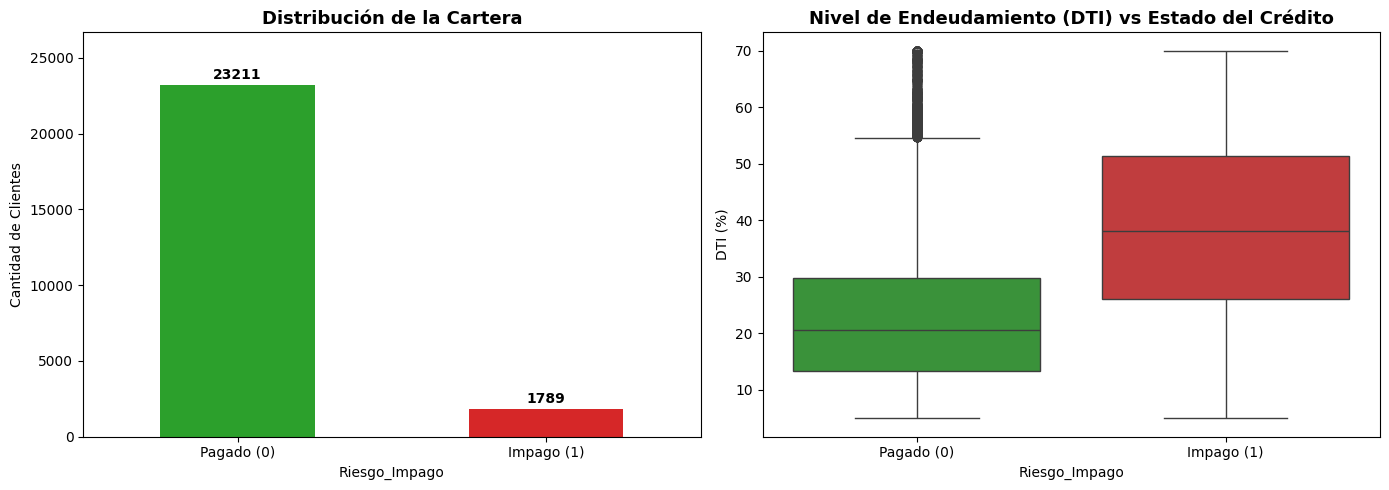

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar el dataset
url = "https://raw.githubusercontent.com/Dannafranchi/EV1_IA/refs/heads/main/E3-Clasificaci%C3%B3n/riesgo_crediticio.csv"
df = pd.read_csv(url)

# 2. Información General, Nulos y Duplicados
print("--- 1. Información General y Duplicados ---")
df.info()
print(f"\nRegistros duplicados: {df.duplicated().sum()}")

# 3. Inconsistencias Lógicas Financieras (Reglas de Negocio)
print("\n--- 2. Validación de Reglas de Negocio ---")
print("Ingresos Anuales <= 0:", (df['Ingreso_Anual'] <= 0).sum())
print("Montos de Préstamo <= 0:", (df['Monto_Prestamo'] <= 0).sum())
print("Puntaje Crédito fuera de rango [300, 850]:", ((df['Puntaje_Credito'] < 300) | (df['Puntaje_Credito'] > 850)).sum())
print("DTI fuera de rango [0, 100%]:", ((df['Relacion_Deuda_Ingreso'] < 0) | (df['Relacion_Deuda_Ingreso'] > 100)).sum())

# 4. Cuantificación de Outliers (Método IQR)
print("\n--- 3. Cuantificación de Outliers (IQR) ---")
numeric_cols = ['Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso']
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))).sum()
    print(f"Outliers en {col}: {outliers} clientes")

# 5. Visualización: Desbalance y Relación con el Target
target_names = ["Pagado (0)", "Impago (1)"]
colores_semaforo = ["#2ca02c", "#d62728"] # Verde para Pagado, Rojo para Impago

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico A: Desbalance de la Cartera
ax0 = df['Riesgo_Impago'].value_counts().plot(kind="bar", color=colores_semaforo, ax=axes[0])
axes[0].set_title("Distribución de la Cartera", fontsize=13, fontweight="bold")
axes[0].set_xticklabels(target_names, rotation=0)
axes[0].set_ylabel("Cantidad de Clientes")
for i, value in enumerate(df['Riesgo_Impago'].value_counts()):
    axes[0].text(i, value + 200, str(value), ha="center", va="bottom", fontweight="bold")
axes[0].set_ylim(0, df['Riesgo_Impago'].value_counts().max() * 1.15)

# Gráfico B: Nivel de Endeudamiento (DTI) vs Riesgo de Impago
sns.boxplot(x='Riesgo_Impago', y='Relacion_Deuda_Ingreso', data=df, ax=axes[1], palette=colores_semaforo)
axes[1].set_title("Nivel de Endeudamiento (DTI) vs Estado del Crédito", fontsize=13, fontweight="bold")
axes[1].set_xticklabels(target_names)
axes[1].set_ylabel("DTI (%)")

plt.tight_layout()
plt.show()

**Conclusiones e Interpretación de Negocio (Hallazgos del EDA):**

1. **Integridad y Reglas de Negocio:** La revisión con `df.info()` y las validaciones lógicas confirman la alta calidad de los 25.000 registros: no hay nulos, no hay duplicados y las variables respetan estrictamente sus rangos financieros (Puntaje de Crédito entre 300 y 850, y DTI entre 0 y 100%). Esto indica que los sistemas de captura de datos de la institución son robustos.
2. **Presencia de Outliers Reales:** La cuantificación matemática mediante el Rango Intercuartílico (IQR) y los gráficos muestran valores extremos que son naturales en el negocio financiero. Por ejemplo, existen clientes con niveles de endeudamiento críticos y clientes con ingresos de hasta \$348.135 dólares. Además, visualmente comprobamos que un mayor DTI tiende a asociarse con casos de impago. Estos perfiles no son errores, por lo que no deben ser eliminados, pero nos obligan a usar estrategias robustas (como la imputación por mediana) en la siguiente fase.
3. **El Desafío del Desbalance (El sesgo de la cartera):** El 92.8% de los clientes son cumplidores (Clase 0), mientras que solo el 7.2% incurre en impago (Clase 1).
  - *Impacto en el Negocio:* Si creamos un modelo "ingenuo" que apruebe todos los créditos, el banco tendría un 92.8% de **Exactitud (Accuracy)**, pero se tragaría todo el costo financiero de los impagos (pérdidas de \$1.500.000 de capital por cada caso).
  - *Decisión Estratégica:* Este desbalance nos obliga comercialmente a no enfocarnos en la Exactitud global, sino en penalizar duramente a los algoritmos que no detecten a este 7.2% minoritario. El modelo debe estar hiper-enfocado en capturar los Falsos Negativos (riesgosos aprobados por error).

## Fase 2: Limpieza y Tratamiento de Datos (Pipeline Automatizado)

En esta fase prepararemos los datos mediante un `Pipeline` de Scikit-Learn para garantizar un procesamiento ordenado, reproducible y evitar la fuga de datos (*Data Leakage*) al momento de modelar.

**Decisiones Técnicas Fundamentadas:**
1. **Limpieza Inicial:** Se elimina la columna `Unnamed: 0`, ya que es un identificador sin valor predictivo.
2. **Estrategia de Imputación (`SimpleImputer`):** Aunque el dataset actual no posee nulos, el flujo en producción debe estar protegido. Se configura la imputación utilizando la **mediana** (`strategy='median'`) debido a la presencia de *outliers* financieros (clientes de ingresos extremadamente altos) que distorsionarían un relleno basado en el promedio clásico.
3. **Estrategia de Escalado (`RobustScaler`):** Se integra un escalador basado en rangos intercuartílicos por **buenas prácticas de ingeniería de datos y reutilización del pipeline**. Sabemos teóricamente que los Árboles de Decisión son invariantes a la escala (el escalado no los afecta ni los mejora); sin embargo, incluir este paso garantiza que el pipeline esté listo para evaluar a futuro modelos que sí son estrictamente sensibles a la magnitud de los *outliers*.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

# 1. Eliminar columna de índice que no aporta valor al negocio
if 'Unnamed: 0' in df.columns:
    df = df.drop('Unnamed: 0', axis=1)

# 2. Separar características (X) y variable objetivo (y)
X = df.drop('Riesgo_Impago', axis=1)
y = df['Riesgo_Impago']

# 3. Identificar las columnas numéricas
numeric_features = X.columns.tolist()

# 4. Construir el transformador numérico coherente con los outliers
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Protege contra nulos usando la mediana
    ('scaler', RobustScaler())                     # Buenas prácticas: escalado robusto a outliers
])

# 5. Ensamblar el preprocesador final con ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features)
    ]
)

print("Pipeline de preprocesamiento (Imputación por mediana + RobustScaler) configurado con éxito.")
print("Variables a transformar:", numeric_features)

Pipeline de preprocesamiento (Imputación por mediana + RobustScaler) configurado con éxito.
Variables a transformar: ['Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso']


## Fase 3: Construcción y Optimización del Modelo

Con los datos procesados, procedemos a entrenar nuestro algoritmo predictivo tomando decisiones críticas acordes al problema de negocio:

**1. División Estratificada:**
Al dividir los datos en entrenamiento (80%) y prueba (20%), usamos `stratify=y`. Esto garantiza que ambos conjuntos mantengan exactamente la proporción real (92.8% cumplidores vs 7.2% impagos).

**2. Modelo Línea Base:**
Entrenaremos un Árbol de Decisión (`DecisionTreeClassifier`) con sus parámetros por defecto como punto de comparación inicial.

**3. Modelo Optimizado (Tuning de Hiperparámetros):**
Ajustaremos 4 hiperparámetros clave mediante `GridSearchCV`:
* `criterion`: Para evaluar la calidad de las divisiones ('gini' o 'entropy').
* `max_depth`: Para controlar la profundidad máxima del árbol y evitar el sobreajuste.
* `min_samples_leaf`: Para asegurar un volumen mínimo de clientes en las hojas finales del árbol, dándole robustez estadística.
* `class_weight`: **El parámetro más importante del negocio.** Al usar `'balanced'`, obligamos al modelo a prestar mucha más atención matemática a la clase minoritaria (los impagos).
* **Métrica de optimización (`scoring='average_precision'`):** En lugar de usar solo Recall (que podría favorecer un modelo que rechace a todos los clientes para no correr riesgos), optimizamos basándonos en PR-AUC (Average Precision). Esta es la métrica robusta para clases fuertemente desbalanceadas, ya que encuentra el equilibrio real en la detección de la clase minoritaria.

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

# 1. División de datos (Train/Test) con estratificación
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=29, stratify=y
)
print("Distribución en Train (Riesgo_Impago):\n", y_train.value_counts(normalize=True).round(3))
print("Distribución en Test (Riesgo_Impago):\n", y_test.value_counts(normalize=True).round(3))

# 2. Modelo Línea Base
pipeline_base = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=29))
])
pipeline_base.fit(X_train, y_train)
print("\nModelo Línea Base entrenado con éxito.")

# 3. Modelo Optimizado
pipeline_opt = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=29))
])

# Definición de los 4 hiperparámetros a evaluar (Cambio: min_samples_leaf)
param_grid = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [3, 5, 7, 10],
    'classifier__min_samples_leaf': [5, 10, 20, 50],
    'classifier__class_weight': [None, 'balanced']
}

# Validación cruzada de 5 pliegues
cv_stratificada = StratifiedKFold(n_splits=5, shuffle=True, random_state=29)

# Cambio clave: scoring='average_precision' (PR-AUC)
grid_search = GridSearchCV(
    pipeline_opt,
    param_grid,
    cv=cv_stratificada,
    scoring='average_precision',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

print("\nModelo Optimizado entrenado con éxito.")
print("Mejores hiperparámetros encontrados:")
for param, value in grid_search.best_params_.items():
    print(f" - {param.replace('classifier__', '')}: {value}")

Distribución en Train (Riesgo_Impago):
 Riesgo_Impago
0    0.928
1    0.072
Name: proportion, dtype: float64
Distribución en Test (Riesgo_Impago):
 Riesgo_Impago
0    0.928
1    0.072
Name: proportion, dtype: float64

Modelo Línea Base entrenado con éxito.

Modelo Optimizado entrenado con éxito.
Mejores hiperparámetros encontrados:
 - class_weight: balanced
 - criterion: entropy
 - max_depth: 10
 - min_samples_leaf: 50


## Fase 4: Evaluación e Interpretación de Resultados en el Negocio

### 1. Justificación de las Métricas Seleccionadas
Debido al severo desbalance de la cartera (92.8% de clientes al día vs 7.2% en impago), el rendimiento de los modelos se evalúa bajo las siguientes dos métricas:

* **Recall (Sensibilidad de la Clase 1):** Es la métrica reina para este proyecto. Dado que clasificar a un cliente riesgoso como cumplidor (Falso Negativo) le cuesta al banco **\$1.500.000** en pérdida de capital, frente a los **\$200.000** de pérdida en intereses por un cliente viable rechazado (Falso Positivo), nuestro objetivo matemático prioritario es maximizar la detección de la clase minoritaria.
* **PR-AUC (Área bajo la curva Precision-Recall):** Reemplazamos la métrica tradicional ROC-AUC debido a que, en datasets desbalanceados, esta genera un optimismo engañoso al incluir la enorme masa de Verdaderos Negativos en su cálculo. PR-AUC se enfoca exclusivamente en la clase positiva (el riesgo), evaluando el equilibrio real entre capturar morosos y no generar falsas alarmas.


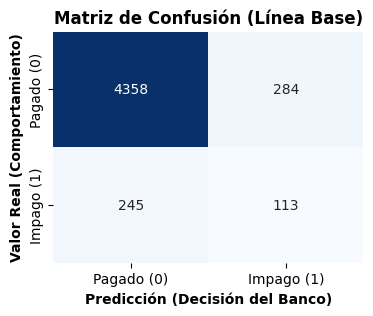

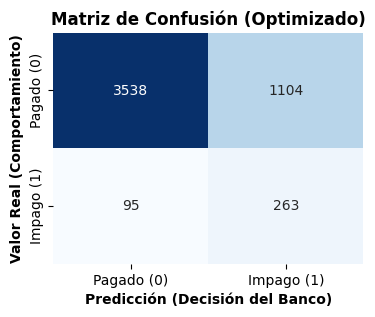


--- MODELO LÍNEA BASE ---
Recall (Detección de Impagos): 0.316
PR-AUC (Average Precision): 0.139
Costo Financiero Estimado: $424,300,000

--- MODELO OPTIMIZADO ---
Recall (Detección de Impagos): 0.735
PR-AUC (Average Precision): 0.399
Costo Financiero Estimado: $363,300,000


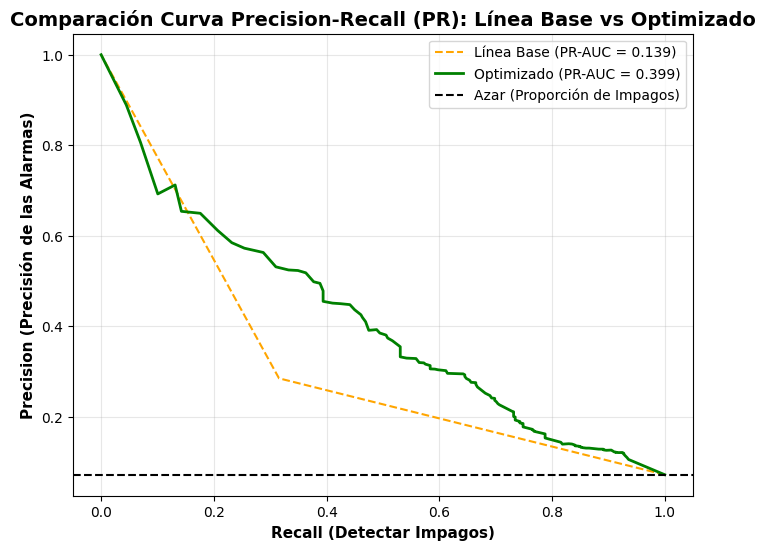

In [ ]:
from sklearn.metrics import confusion_matrix, average_precision_score, recall_score, precision_recall_curve
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Generar predicciones para ambos modelos usando el set de prueba
y_pred_base = pipeline_base.predict(X_test)
y_proba_base = pipeline_base.predict_proba(X_test)[:, 1]

y_pred_opt = grid_search.predict(X_test)
y_proba_opt = grid_search.predict_proba(X_test)[:, 1]

target_names = ["Pagado (0)", "Impago (1)"]

# 2. Función gráfica para la Matriz de Confusión
def view_matrix(y_test, y_pred, model_desc="Línea Base"):
    plt.figure(figsize=(4, 3))
    sns.heatmap(
        confusion_matrix(y_test, y_pred),
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_names,
        yticklabels=target_names,
        cbar=False,
    )
    plt.xlabel("Predicción (Decisión del Banco)", fontsize=10, fontweight="bold")
    plt.ylabel("Valor Real (Comportamiento)", fontsize=10, fontweight="bold")
    plt.title(f"Matriz de Confusión ({model_desc})", fontsize=12, fontweight="bold")
    plt.show()

# 3. Mostrar Matrices de Confusión Gráficas
view_matrix(y_test, y_pred_base, "Línea Base")
view_matrix(y_test, y_pred_opt, "Optimizado")

# 4. Cálculo de Métricas y Costos de Negocio
def calcular_costo_negocio(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    TN, FP, FN, TP = cm.ravel()
    costo_total = (FP * 200000) + (FN * 1500000)
    return costo_total

print("\n--- MODELO LÍNEA BASE ---")
print(f"Recall (Detección de Impagos): {recall_score(y_test, y_pred_base):.3f}")
print(f"PR-AUC (Average Precision): {average_precision_score(y_test, y_proba_base):.3f}")
print(f"Costo Financiero Estimado: ${calcular_costo_negocio(y_test, y_pred_base):,}")

print("\n--- MODELO OPTIMIZADO ---")
print(f"Recall (Detección de Impagos): {recall_score(y_test, y_pred_opt):.3f}")
print(f"PR-AUC (Average Precision): {average_precision_score(y_test, y_proba_opt):.3f}")
print(f"Costo Financiero Estimado: ${calcular_costo_negocio(y_test, y_pred_opt):,}")

# 5. Gráfico de Curva Precision-Recall (PR)
precision_base, recall_base, _ = precision_recall_curve(y_test, y_proba_base)
precision_opt, recall_opt, _ = precision_recall_curve(y_test, y_proba_opt)

plt.figure(figsize=(8, 6))
plt.plot(recall_base, precision_base, label=f"Línea Base (PR-AUC = {average_precision_score(y_test, y_proba_base):.3f})", color="orange", linestyle="--")
plt.plot(recall_opt, precision_opt, label=f"Optimizado (PR-AUC = {average_precision_score(y_test, y_proba_opt):.3f})", color="green", linewidth=2)
# La línea base aleatoria depende de la proporción de la clase minoritaria (aprox 0.072)
plt.axhline(y=0.072, color='k', linestyle='--', label="Azar (Proporción de Impagos)")

plt.xlabel("Recall (Detectar Impagos)", fontsize=11, fontweight="bold")
plt.ylabel("Precision (Precisión de las Alarmas)", fontsize=11, fontweight="bold")
plt.title("Comparación Curva Precision-Recall (PR): Línea Base vs Optimizado", fontsize=14, fontweight="bold")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.show()

## 2. Interpretación de la Matriz de Confusión e Impacto Financiero

Al evaluar las matrices sobre el conjunto de prueba (5.000 solicitudes nuevas), traducimos las predicciones técnicas directamente a impacto financiero para la institución.

Para dar contexto: Un "modelo ingenuo" que apruebe todos los créditos costaría **\$537 Millones** en pérdidas de capital (358 morosos x \$1.5M).

**Modelo Línea Base (DecisionTree por defecto):**
*   **Falsos Negativos (245 casos):** El modelo aprobó erróneamente a 245 clientes que finalmente cayeron en impago. Pérdida por capital: 245 x \$1.5M = \$367.5 Millones.
*   **Falsos Positivos (284 casos):** El modelo rechazó a 284 clientes que sí iban a pagar. Pérdida por intereses: 284 x \$200k = \$56.8 Millones.
*   **Costo Financiero Total de Ineficiencia: \$424.3 Millones.**
*   *Problema:* El modelo base ignora a la minoría riesgosa, obteniendo un Recall muy pobre (0.316) y un PR-AUC de solo 0.139.

**Modelo Optimizado (GridSearchCV enfocado en Average Precision):**
*   **Falsos Negativos (95 casos):** Gracias a la optimización enfocada en el riesgo, el modelo logró reducir drásticamente los créditos malos aprobados a menos de 100 casos. La pérdida de capital bajó a: 95 x \$1.5M = \$142.5 Millones.
*   **Falsos Positivos (1104 casos):** Al volverse mucho más estricto para proteger el capital, el algoritmo rechazó erróneamente a ~1100 clientes viables (aprox. 19% de los buenos). Pérdida por intereses: 1104 x \$200k = \$220.8 Millones.
*   **Costo Financiero Total de Ineficiencia: \$363.3 Millones.**

## 3. Conclusión Ejecutiva

Rechazar a más clientes buenos (19% de Falsos Positivos) **es el costo comercial de proteger el capital del banco**. Al enfocar el modelo en la detección temprana del riesgo (PR-AUC), la métrica de Recall se eleva a un 0.735, logrando atrapar a casi el 75% de los morosos.

Esta mejora estratégica en la detección le genera a la institución financiera un **ahorro neto de \$61 Millones** (\$424.3M - \$363.3M) en comparación con el modelo base, y mejora en casi un tercio el desastroso escenario de "aprobar a todos" (\$537 Millones).